# 07 - Exploratory Data Analysis (EDA)

Each section asks one **business question** and answers it with the cleaned data in `silver.listings`.

Two rules used throughout:
- **Median, not mean.** Prices are right-skewed, so the median describes a typical listing better (decision from notebook 02).
- **Compare within each city.** Price levels differ up to 3.6x between cities, so mixing them hides the real patterns.

After running each section, write the answer in the **Finding** cell below it.

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyodbc
from matplotlib.colors import LinearSegmentedColormap
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

DRIVER = sorted(d for d in pyodbc.drivers() if "ODBC Driver" in d and "SQL Server" in d)[-1]
conn_str = (
    f"DRIVER={{{DRIVER}}};SERVER=.;DATABASE=AirbnbEurope;"
    "Trusted_Connection=yes;TrustServerCertificate=yes;"
)
engine = create_engine(URL.create("mssql+pyodbc", query={"odbc_connect": conn_str}))

df = pd.read_sql("SELECT * FROM silver.listings", engine)
df["price_per_person"] = df["price_eur"] / df["person_capacity"]
print(df.shape)

(51689, 28)


## Chart style
One consistent look for every chart: light background, quiet grid, and a fixed color order
(blue, orange, aqua) so the same category always has the same color.

In [12]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, RED, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#f0efec"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA]),
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2, "legend.frameon": False,
})

## Q1: Which cities are the most expensive?
A listing that sleeps 6 costs more than one that sleeps 2, so we also look at the **price per person**.

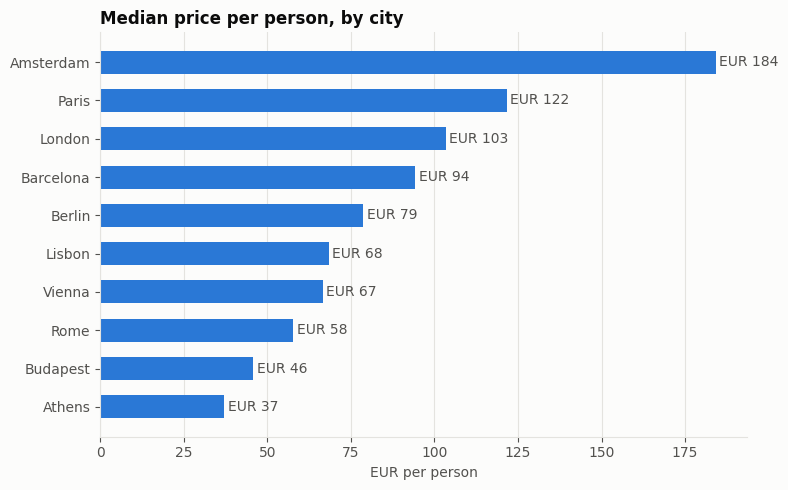

,listings,median_price,median_price_per_person
city,,,
Amsterdam,2080,460.2,184.3
Paris,6687,317.6,121.6
London,9986,260.4,103.4
Barcelona,2829,208.3,94.3
Berlin,2482,191.2,78.8
Lisbon,5763,225.4,68.5
Vienna,3534,208.5,66.6
Rome,9027,182.6,57.8
Budapest,4022,153.0,45.8


In [13]:
by_city = df.groupby("city").agg(
    listings=("listing_id", "size"),
    median_price=("price_eur", "median"),
    median_price_per_person=("price_per_person", "median"),
).sort_values("median_price_per_person")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(by_city.index, by_city["median_price_per_person"], color=BLUE, height=0.6)
for y, v in enumerate(by_city["median_price_per_person"]):
    ax.text(v + 1, y, f"EUR {v:.0f}", va="center", color=INK_2)
ax.set_title("Median price per person, by city")
ax.set_xlabel("EUR per person")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

by_city.round(1).sort_values("median_price_per_person", ascending=False)

**Finding:** Amsterdam is by far the most expensive city: EUR 184 per person (median listing EUR 460),
about **5x Athens**, the cheapest city (EUR 37 per person, median listing EUR 128).
Ranking by price per person changes the order compared with the total price: Lisbon has a higher total
price (EUR 225) than Barcelona (EUR 208) and Berlin (EUR 191), but a lower price per person (EUR 68),
which means Lisbon listings are larger on average.

## Q2: Are weekends more expensive than weekdays?
For each city: how much higher (or lower) is the median weekend price than the median weekday price?

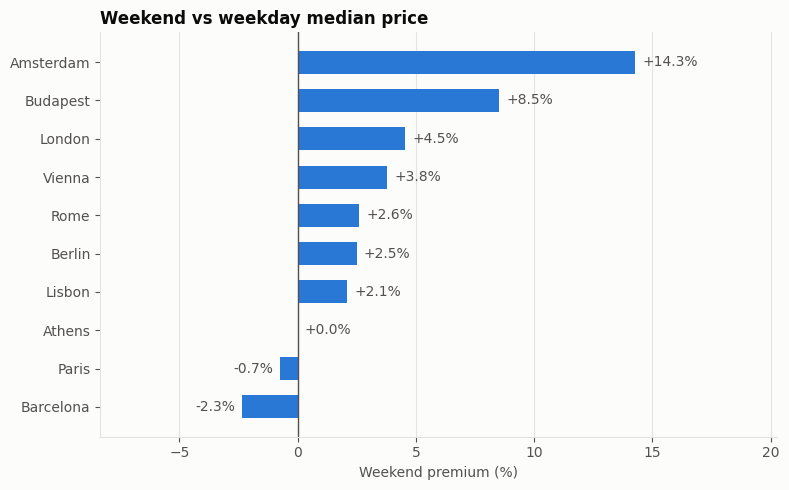

day_type,weekdays,weekends,weekend_premium_pct
city,,,
Barcelona,208.5,203.6,-2.3
Paris,318.5,316.2,-0.7
Athens,127.7,127.7,0.0
Lisbon,223.0,227.7,2.1
Berlin,187.7,192.3,2.5
Rome,179.8,184.5,2.6
Vienna,204.3,212.0,3.8
London,256.4,268.0,4.5
Budapest,147.5,160.0,8.5


In [14]:
by_day = df.pivot_table(index="city", columns="day_type", values="price_eur", aggfunc="median")
by_day["weekend_premium_pct"] = (by_day["weekends"] / by_day["weekdays"] - 1) * 100
by_day = by_day.sort_values("weekend_premium_pct")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(by_day.index, by_day["weekend_premium_pct"], color=BLUE, height=0.6)
ax.axvline(0, color=INK_2, linewidth=1)
lo, hi = by_day["weekend_premium_pct"].min(), by_day["weekend_premium_pct"].max()
ax.set_xlim(min(lo, 0) - 6, max(hi, 0) + 6)  # room for the labels on both sides
for y, v in enumerate(by_day["weekend_premium_pct"]):
    ax.text(v + (0.3 if v >= 0 else -0.3), y, f"{v:+.1f}%", va="center",
            ha="left" if v >= 0 else "right", color=INK_2)
ax.set_title("Weekend vs weekday median price")
ax.set_xlabel("Weekend premium (%)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

by_day.round(1)

**Finding:** Weekends are more expensive in 7 of the 10 cities, but the premium is usually small (under 5%).
Two cities stand out: **Amsterdam (+14.3%)** and **Budapest (+8.5%)**.
Athens shows no difference (0.0%), and Barcelona (-2.3%) and Paris (-0.7%) are slightly cheaper at weekends;
these small negative differences may not be meaningful.

## Q3: How much does the room type change the price?

Listings per room type:
room_type
Entire home/apt    32636
Private room       18687
Shared room          366
Name: count, dtype: int64 



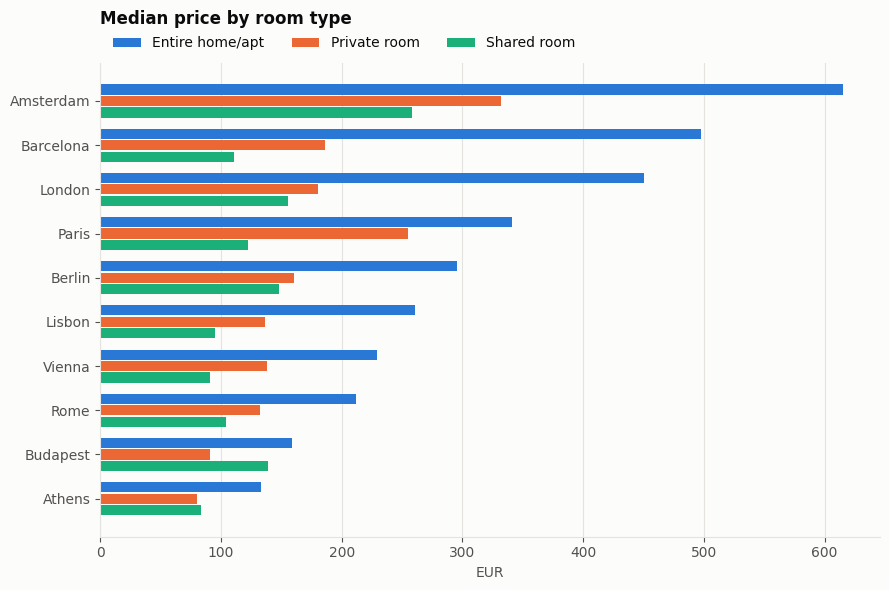

room_type,Entire home/apt,Private room,Shared room,entire_vs_private
city,,,,
Athens,133.3,80.1,83.4,1.7
Budapest,158.6,91.2,139.1,1.7
Rome,212.0,132.6,103.8,1.6
Vienna,229.3,138.4,91.0,1.7
Lisbon,260.3,136.3,94.9,1.9
Berlin,295.6,160.1,148.4,1.8
Paris,341.2,254.9,122.1,1.3
London,450.2,180.4,155.1,2.5
Barcelona,497.6,186.2,111.0,2.7


In [15]:
print("Listings per room type:")
print(df["room_type"].value_counts(), "\n")

by_room = df.pivot_table(index="city", columns="room_type", values="price_eur", aggfunc="median")
by_room = by_room.loc[by_room["Entire home/apt"].sort_values().index]
room_types = ["Entire home/apt", "Private room", "Shared room"]

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(by_room))
h = 0.26
for i, (room, color) in enumerate(zip(room_types, [BLUE, ORANGE, AQUA])):
    ax.barh(y + (1 - i) * h, by_room[room], height=h - 0.03, color=color, label=room)
ax.set_yticks(y, by_room.index)
ax.set_title("Median price by room type")
ax.set_xlabel("EUR")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
ax.set_title("Median price by room type", pad=28)
plt.tight_layout()
plt.show()

by_room["entire_vs_private"] = by_room["Entire home/apt"] / by_room["Private room"]
by_room.round(1)

**Finding:** Entire homes dominate the market (63% of listings), private rooms are 36%, and shared rooms are rare (0.7%, 366 listings).
An entire home costs between **1.3x (Paris)** and **2.7x (Barcelona)** the price of a private room.
Paris private rooms are unusually expensive (EUR 255), which narrows the gap there.
Shared rooms are sometimes priced above private rooms (Athens, Budapest), but there are too few of them
for this to be reliable.**Finding:** _(write your answer here)_

## Q4: Does being close to the city center raise the price?
Each city has a different price level, so each listing's price is divided by **its city's median**.
A value of 1.2 means "20% above a typical listing in that city". This puts all cities on one shared scale.

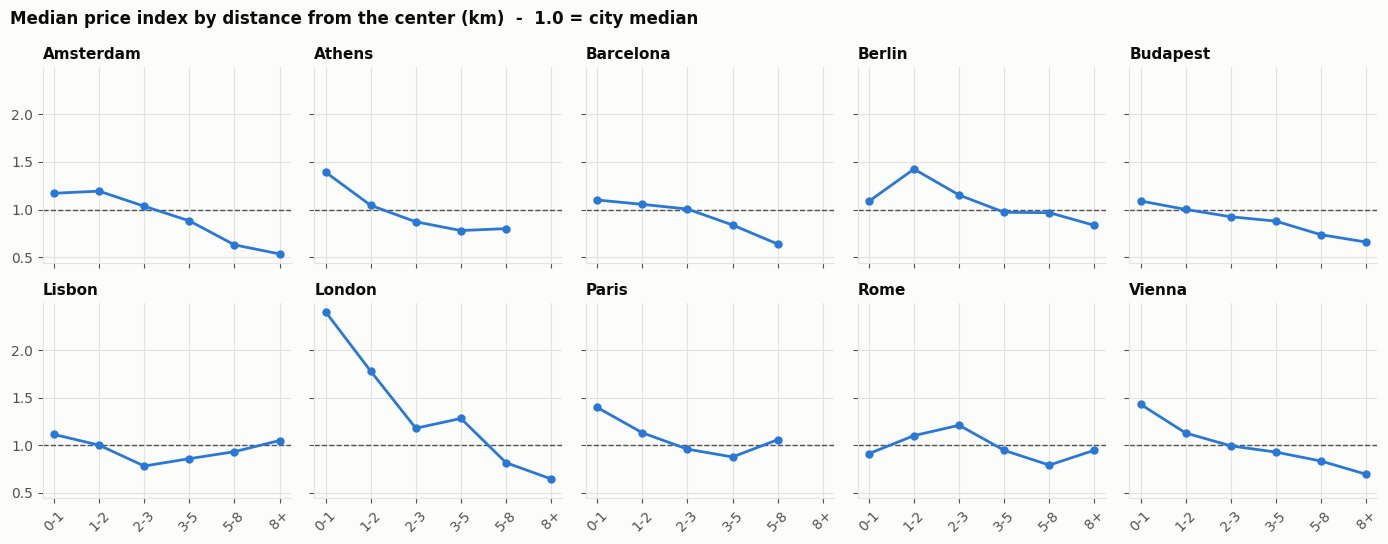

city,Amsterdam,Athens,Barcelona,Berlin,Budapest,Lisbon,London,Paris,Rome,Vienna
dist_band,,,,,,,,,,
0-1,1.17,1.39,1.10,1.09,1.09,1.11,2.40,1.40,0.91,1.43
1-2,1.19,1.04,1.05,1.43,1.00,1.00,1.78,1.13,1.10,1.13
2-3,1.04,0.87,1.01,1.15,0.92,0.78,1.18,0.96,1.21,0.99
3-5,0.88,0.78,0.84,0.97,0.88,0.86,1.28,0.88,0.95,0.93
5-8,0.63,0.80,0.64,0.97,0.74,0.93,0.82,1.06,0.79,0.83
8+,0.53,NaN,NaN,0.83,0.66,1.05,0.65,NaN,0.95,0.70


In [16]:
bands = [0, 1, 2, 3, 5, 8, np.inf]
labels = ["0-1", "1-2", "2-3", "3-5", "5-8", "8+"]
df["dist_band"] = pd.cut(df["dist_center_km"], bins=bands, labels=labels, right=False)
df["price_index"] = df["price_eur"] / df.groupby("city")["price_eur"].transform("median")

by_dist = df.pivot_table(index="dist_band", columns="city", values="price_index",
                         aggfunc="median", observed=False)
counts = df.pivot_table(index="dist_band", columns="city", values="listing_id",
                        aggfunc="size", observed=False)
by_dist = by_dist.where(counts >= 30)  # hide bands with too few listings to trust

cities = sorted(df["city"].unique())
fig, axes = plt.subplots(2, 5, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, city in zip(axes.flat, cities):
    ax.axhline(1, color=INK_2, linewidth=1, linestyle="--")
    ax.plot(labels, by_dist[city].values, color=BLUE, marker="o", markersize=5)
    ax.set_title(city, fontsize=11)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Median price index by distance from the center (km)  -  1.0 = city median",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

by_dist.round(2)

**Finding:** In most cities, prices fall as distance from the center grows.
The effect is strongest in **London**: listings within 1 km cost 2.4x the city median, while listings beyond 8 km cost 0.65x
(about 3.7 times less). Amsterdam (1.17 to 0.53) and Vienna (1.43 to 0.70) follow the same clear pattern.
There are exceptions: in **Rome** prices peak at 2-3 km rather than in the very center, in **Berlin** they peak at 1-2 km,
and in **Lisbon** the pattern is U-shaped (prices rise again beyond 8 km).
These exceptions may reflect each city's layout (for example several centers in Berlin, or coastal areas outside Lisbon),
but this is a hypothesis that the data does not prove.

## Q5: Do superhosts charge more, and are their guests happier?
Not every answer needs a chart: a small table is clearer here.

In [17]:
df.groupby("host_is_superhost").agg(
    listings=("listing_id", "size"),
    median_price=("price_eur", "median"),
    median_price_index=("price_index", "median"),
    avg_guest_satisfaction=("guest_satisfaction", "mean"),
    avg_cleanliness=("cleanliness_rating", "mean"),
).round(2)

,listings,median_price,median_price_index,avg_guest_satisfaction,avg_cleanliness
host_is_superhost,,,,,
False,38461,217.40,0.99,91.16,9.24
True,13228,197.04,1.02,96.90,9.83


**Finding:** Superhosts (26% of listings) have clearly happier guests: guest satisfaction 96.9 vs 91.2 and cleanliness 9.83 vs 9.24.
However, they do **not** charge more. Their raw median price is lower (EUR 197 vs EUR 217), but compared with their own city's median
the prices are almost the same (index 1.02 vs 0.99). The lower raw price only happens because superhosts are more common in cheaper cities.

## Q6: Do professional hosts behave differently from individuals?
- **Individual:** 1 listing
- **Small:** 2-4 listings
- **Professional:** more than 4 listings

In [18]:
df["host_type"] = np.select(
    [df["host_has_over_4_listings"].astype(bool), df["host_has_2_to_4_listings"].astype(bool)],
    ["Professional (5+)", "Small (2-4)"],
    default="Individual (1)",
)

df.groupby("host_type").agg(
    listings=("listing_id", "size"),
    share_entire_home=("room_type", lambda s: (s == "Entire home/apt").mean()),
    median_price_index=("price_index", "median"),
    avg_guest_satisfaction=("guest_satisfaction", "mean"),
    superhost_share=("host_is_superhost", "mean"),
).round(2)

,listings,share_entire_home,median_price_index,avg_guest_satisfaction,superhost_share
host_type,,,,,
Individual (1),18525,0.69,0.96,94.49,0.27
Professional (5+),18099,0.65,1.11,90.09,0.19
Small (2-4),15065,0.53,0.95,93.39,0.32


**Finding:** Professional hosts (5+ listings) manage 35% of all listings. They price **11% above** the city median (index 1.11),
while individual and small hosts price slightly below it (0.96 and 0.95).
Despite the higher prices, their guests are less satisfied (90.1 vs 94.5 for individuals), and fewer of them are superhosts
(19% vs 27% for individuals and 32% for small hosts).

## Q7: Is a bigger place cheaper per person?

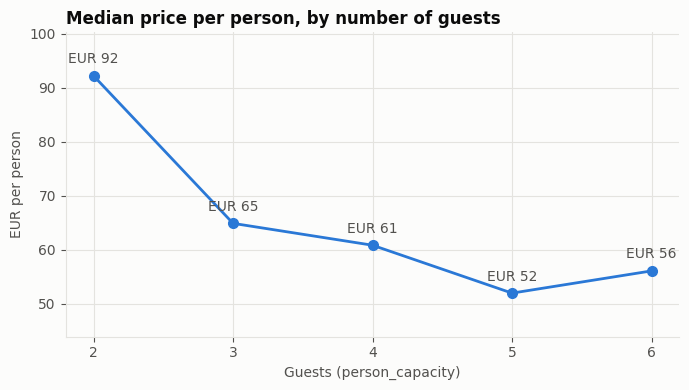

,listings,median_price,median_price_per_person
person_capacity,,,
2,24321,184.5,92.2
3,6164,194.6,64.9
4,13999,243.3,60.8
5,2935,259.7,51.9
6,4270,336.3,56.1


In [19]:
by_capacity = df.groupby("person_capacity").agg(
    listings=("listing_id", "size"),
    median_price=("price_eur", "median"),
    median_price_per_person=("price_per_person", "median"),
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(by_capacity.index, by_capacity["median_price_per_person"], color=BLUE, marker="o", markersize=7)
for x, v in zip(by_capacity.index, by_capacity["median_price_per_person"]):
    ax.annotate(f"EUR {v:.0f}", (x, v), textcoords="offset points", xytext=(0, 9), ha="center", color=INK_2)
ax.set_title("Median price per person, by number of guests")
ax.set_xlabel("Guests (person_capacity)")
ax.set_ylabel("EUR per person")
ax.set_xticks(by_capacity.index)
ax.margins(y=0.2)
plt.tight_layout()
plt.show()

by_capacity.round(1)

**Finding:** Larger listings are much cheaper per person. The median price per person drops from EUR 92 for 2 guests
to EUR 52 for 5 guests (about 44% less), even though the total price rises from EUR 185 to EUR 260.
Listings for 6 guests are slightly more expensive per person (EUR 56) than those for 5.

## Q8: Which features matter most once cities are separated?
Notebook 02 found weak correlations, partly because all cities were mixed together.
Here the correlation is computed **inside each city**.

We use **Spearman** correlation: it compares the *ranking* of values instead of the raw values,
so a few very expensive listings cannot dominate the result.
Blue = higher feature, higher price. Red = higher feature, lower price.

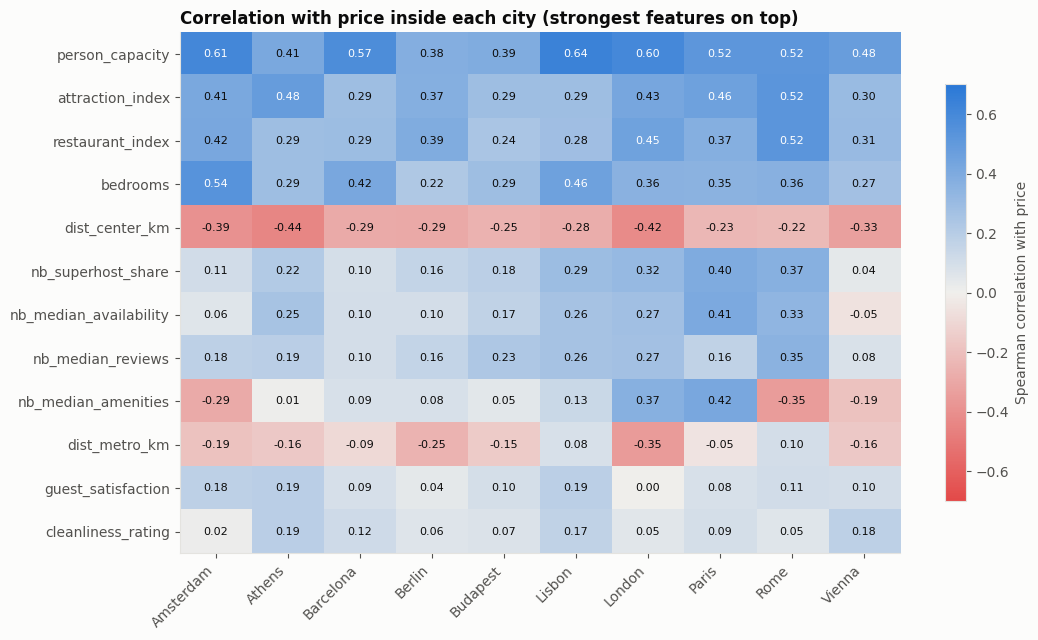

,Amsterdam,Athens,Barcelona,Berlin,Budapest,Lisbon,London,Paris,Rome,Vienna
person_capacity,0.61,0.41,0.57,0.38,0.39,0.64,0.60,0.52,0.52,0.48
attraction_index,0.41,0.48,0.29,0.37,0.29,0.29,0.43,0.46,0.52,0.30
restaurant_index,0.42,0.29,0.29,0.39,0.24,0.28,0.45,0.37,0.52,0.31
bedrooms,0.54,0.29,0.42,0.22,0.29,0.46,0.36,0.35,0.36,0.27
dist_center_km,-0.39,-0.44,-0.29,-0.29,-0.25,-0.28,-0.42,-0.23,-0.22,-0.33
nb_superhost_share,0.11,0.22,0.10,0.16,0.18,0.29,0.32,0.40,0.37,0.04
nb_median_availability,0.06,0.25,0.10,0.10,0.17,0.26,0.27,0.41,0.33,-0.05
nb_median_reviews,0.18,0.19,0.10,0.16,0.23,0.26,0.27,0.16,0.35,0.08
nb_median_amenities,-0.29,0.01,0.09,0.08,0.05,0.13,0.37,0.42,-0.35,-0.19
dist_metro_km,-0.19,-0.16,-0.09,-0.25,-0.15,0.08,-0.35,-0.05,0.10,-0.16


In [20]:
features = [
    "bedrooms", "person_capacity", "dist_center_km", "dist_metro_km", "attraction_index",
    "restaurant_index", "cleanliness_rating", "guest_satisfaction",
    "nb_superhost_share", "nb_median_availability", "nb_median_reviews", "nb_median_amenities",
]

within_city = pd.DataFrame({
    city: group[features].corrwith(group["price_eur"], method="spearman")
    for city, group in df.groupby("city")
})
within_city = within_city.loc[within_city.abs().mean(axis=1).sort_values(ascending=False).index]

cmap = LinearSegmentedColormap.from_list("diverging", [RED, NEUTRAL, BLUE])
fig, ax = plt.subplots(figsize=(11, 6.5))
im = ax.imshow(within_city.values, cmap=cmap, vmin=-0.7, vmax=0.7, aspect="auto")
ax.set_xticks(range(len(within_city.columns)), within_city.columns, rotation=45, ha="right")
ax.set_yticks(range(len(within_city.index)), within_city.index)
ax.grid(False)
for i in range(within_city.shape[0]):
    for j in range(within_city.shape[1]):
        v = within_city.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.45 else INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation with price")
ax.set_title("Correlation with price inside each city (strongest features on top)")
plt.tight_layout()
plt.show()

within_city.round(2)

**Finding:** Once cities are analysed separately, the relationships with price become much stronger than in notebook 02.
- **Size matters most:** person_capacity is the strongest (or joint strongest) feature in 8 of the 10 cities (0.38 to 0.64).
  In Athens and Berlin a location feature is slightly stronger (attraction_index 0.48 in Athens, restaurant_index 0.39 in Berlin).
- **Location comes next:** attraction_index and restaurant_index are positive everywhere (0.24 to 0.52),
  and distance from the center is negative in every city (-0.22 to -0.44).
- **Ratings do not drive price:** guest_satisfaction and cleanliness_rating are close to zero (0.00 to 0.19).
- **The neighbourhood features change sign:** nb_superhost_share and nb_median_availability were negative when all cities were mixed
  (-0.25 and -0.22) but are mostly positive within cities (up to 0.40 and 0.41 in Paris). The negative sign came from mixing cities,
  not from a real relationship. nb_median_amenities is inconsistent (positive in Paris and London, negative in Rome and Amsterdam).

## Summary of insights
1. **City is the biggest price driver.** Amsterdam costs about 5x more per person than Athens, so every comparison must be made within each city.
2. **Size and location set the price, not ratings.** Within each city, capacity, bedrooms and closeness to attractions and the center
   explain price far better than guest satisfaction or cleanliness.
3. **Mixing cities hides or reverses patterns (Simpson's paradox).** Superhosts look cheaper overall but price the same as their city;
   neighbourhood features look negative overall but are positive within cities.
4. **Professional hosts charge more for less.** Hosts with 5+ listings price 11% above the city median while their guests are less satisfied.
5. **Groups get better value.** Price per person falls about 44% from 2-guest to 5-guest listings; weekend premiums are small except in Amsterdam (+14%) and Budapest (+8.5%).

**For the dashboard:** a city filter on every page, price per person as a main KPI, a distance-from-center chart per city,
room type and host type comparisons, and superhost vs guest satisfaction.